# Software Engineering for AI Developers: Concurrency and Async

> **Who is this for:** anyone building AI applications that talk to LLM APIs, vector databases or web services, or that crunch data on several CPU cores. It also covers the classic operating-systems and concurrency questions (race conditions, deadlocks, the GIL) that come up in university exams and interviews.
>
> **What you will learn:**
> - **Concurrency vs parallelism**, and **CPU-bound vs I/O-bound** work, and how to tell them apart by measuring
> - **Processes vs threads**: who shares which memory
> - The **GIL**: what it is, why it exists, and the accurate status of **free-threaded CPython** (PEP 703 / PEP 779)
> - **Threading**: race conditions (shown live), `Lock`, `RLock`, `Semaphore`, `Event`, `Condition`, thread-safe queues, and deadlocks (shown safely) with how to avoid them
> - **Multiprocessing**: `Pool`, the cost of pickling, shared memory, and a measured CPU speed-up
> - **`concurrent.futures`**: thread and process pools, `as_completed`, timeouts
> - **`asyncio`**: the event loop, coroutines, tasks, `gather`, timeouts, cancellation, `TaskGroup`, async context managers and generators, queues and semaphores
> - A realistic simulation: **100 LLM calls** done sequentially, with threads and with asyncio, plus **retries with exponential backoff and jitter** and a **token-bucket rate limiter**
> - **Batching** and **backpressure**, a decision table, and common pitfalls
>
> **Prerequisites:** [Python basics](../01_Python/01_basic.ipynb), [Python advanced (generators, reference counting)](../01_Python/03_advanced.ipynb), [Debugging and profiling](04_debugging_and_profiling.ipynb). Helpful: [Advanced FastAPI](../12_FastAPI/02_advanced_fastapi.ipynb), which uses `async def` endpoints.
>
> **Time needed:** about 2.5 to 3 hours.
>
> **Runs on:** CPU, no API key, no internet. All "LLM calls" are simulated with sleeps, so the timings are realistic and free.
>
> **Optional track:** this notebook is part of the university-level fundamentals track. It is recommended for BS/MS AI students and for interview preparation.

## Explained simply

A computer program often spends most of its time **waiting**: for a website to answer, for a file to load, or for an AI model in the cloud to reply. **Concurrency** means doing something useful while you wait, instead of staring at the screen. Think of making breakfast: you put the toast in, and while it toasts you boil the kettle, instead of waiting for the toast before even touching the kettle. Or think of a restaurant: one waiter can look after many tables, because customers spend most of their time reading the menu or eating. **Parallelism** is different: it means having several cooks working at the same moment, which helps when there is a lot of actual *work* (chopping), not just waiting. Python gives you tools for both: threads, processes and `asyncio`. Picking the right one, and keeping them from tripping over each other, is what this notebook teaches.

**A tiny example.** You need answers from an AI service for 10 questions, and each answer takes 1 second to arrive. Asking one question at a time takes 10 × 1 = 10 seconds. Sending all 10 questions at once and waiting for them together takes about 1 second, because the waiting overlaps. Your computer did not work harder. It just stopped waiting in a queue.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Concurrency | juggling many waiting tasks so no time is wasted | sending 100 prompts to an LLM API at once |
| Parallelism | several workers doing real work at the same moment | using all CPU cores to tokenise a big data set |
| Race condition | two workers update the same thing and one update gets lost | a shared "tokens used" counter that comes out too low |

## 0. Setup

In [1]:
import asyncio, os, sys, time, math, random, threading, queue, pickle, sysconfig, tempfile, shutil, warnings, gc
import multiprocessing as mp
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor, as_completed, wait, FIRST_COMPLETED
from concurrent.futures import TimeoutError as FutureTimeout
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(0); np.random.seed(0)
WORK = Path(tempfile.mkdtemp(prefix="se05_"))      # all files we create go here
CPUS = os.cpu_count()
print("Python", sys.version.split()[0], "| logical CPUs:", CPUS)

class Timer:
    """with Timer() as t: ... ; t.seconds  (wall clock, perf_counter)"""
    def __enter__(self):
        self.start = time.perf_counter(); return self
    def __exit__(self, *exc):
        self.seconds = time.perf_counter() - self.start

Python 3.12.3 | logical CPUs: 8


## 1. Concurrency vs parallelism; CPU-bound vs I/O-bound

*In plain English: first find out whether your code is mostly waiting or mostly working.*

**Analogy.** One chef cooking three dishes. They put pasta on to boil, chop vegetables while it boils, and stir the sauce in between. That is **concurrency**: several tasks are *in progress* at the same time, but only one is actively being worked on at any instant. Three chefs each cooking one dish is **parallelism**: several tasks *executing* at the very same instant.

**Definitions.**
- **Concurrency** is *structuring* a program so that multiple tasks can make progress in overlapping time periods (interleaving). It is possible on a single core.
- **Parallelism** is *executing* multiple computations simultaneously. It needs multiple cores or machines.
- A task is **I/O-bound** if it spends most of its time *waiting*: for the network (an LLM API), the disk or a database. Faster CPUs do not help. Overlapping the waits does.
- A task is **CPU-bound** if it spends most of its time *computing*: tokenising a corpus, feature engineering, or pure-Python maths. Only more cores (or a faster algorithm) help.

```
Concurrency (1 core, interleaved)        Parallelism (2 cores, simultaneous)
core 0: A A B B A C C B A                core 0: A A A A A
                                         core 1: B B B B B
```

| | I/O-bound | CPU-bound |
|---|---|---|
| AI examples | calling an LLM or embedding API, querying a vector DB, downloading data | tokenising a corpus, pure-Python feature engineering, JSON parsing of huge files |
| Bottleneck | latency of the other side | CPU cycles |
| What helps | **concurrency**: threads or asyncio | **parallelism**: processes, or vectorised / native code |

**How to tell, by measuring:** compare wall-clock time with CPU time (`time.thread_time()`). If CPU ≈ wall, the code is computing. If CPU ≪ wall, it is waiting.

In [2]:
def fake_api_call():
    time.sleep(0.2)                              # waiting for the network

def tokenise_corpus():
    return sum(len(w) for w in ("the quick brown fox jumps " * 120_000).split())   # computing

for fn in (fake_api_call, tokenise_corpus):
    cpu0 = time.thread_time()
    with Timer() as t:
        fn()
    cpu = time.thread_time() - cpu0
    kind = "CPU-bound" if cpu > 0.05 * t.seconds else "I/O-bound"     # >5% of the time on the CPU
    print(f"{fn.__name__:16s} wall={t.seconds:.3f}s  cpu={cpu:.3f}s  cpu/wall={cpu / t.seconds:5.1%}  ->  {kind}")

fake_api_call    wall=0.204s  cpu=0.000s  cpu/wall= 0.0%  ->  I/O-bound
tokenise_corpus  wall=0.382s  cpu=0.156s  cpu/wall=40.9%  ->  CPU-bound


**What just happened?** The fake API call spent 0.2 s of wall time and almost no CPU time (about 0%): it is I/O-bound. The tokeniser spent a large share of its wall time on the CPU: it is CPU-bound. On an idle machine its CPU time is almost equal to its wall time. On a busy machine the share is lower, because other programs also get turns on the core, so we use a low cut-off (5%) that a waiting task never reaches. This one measurement decides which tool to use for the rest of this notebook.

## 2. Processes vs threads: the memory model

*In plain English: processes are separate houses; threads are rooms in one house.*

- A **process** is a running program with its **own private address space** (memory), its own Python interpreter and, in CPython, its own GIL. Processes are isolated: a crash or a memory bug in one does not corrupt the others. To exchange data they must use **IPC** (inter-process communication): pipes, queues, sockets or shared-memory segments. In Python, sending objects usually means **pickling** them.
- A **thread** is an independent flow of execution **inside** a process. All threads of a process **share the same memory** (globals, heap objects), so communication is free, and **races** are possible.

```
Process A                           Process B
+--------------------------------+  +----------------------+
| heap: model, caches, globals   |  | its OWN heap (copy   |
|  ^        ^        ^           |  |  or fresh)           |
| thread1 thread2 thread3        |  | thread1              |
| (own stack, shared heap)       |  |                      |
+--------------------------------+  +----------------------+
          <---- IPC: pipe / queue / shared memory (pickling) ---->
```

| | Thread | Process |
|---|---|---|
| Memory | shared with the other threads | separate |
| Start-up cost | ~tens of µs | ~tens to hundreds of ms (a new interpreter, imports) |
| Communication | direct (shared objects) | IPC, pickling |
| Crash isolation | none: a segfault kills them all | yes |
| Parallel Python bytecode in standard CPython? | no (the GIL) | **yes** |

A notebook cannot send functions defined in its cells to a **spawned** process, because the child cannot import them. So we write a small **worker module** into a temporary folder and import it from there. In real projects, worker functions should live in a module anyway.

In [3]:
WORKER_SRC = r"""
import os, time, math
from multiprocessing import shared_memory

SEEN = []                                    # a module-level global, private to each process

def remember(x):
    time.sleep(0.05)
    SEEN.append(x)
    return os.getpid(), len(SEEN)

def count_primes(bounds):
    lo, hi = bounds                          # CPU-bound pure-Python work
    count = 0
    for n in range(max(lo, 2), hi):
        if n % 2 == 0 and n != 2:
            continue
        r = int(math.isqrt(n))
        for d in range(3, r + 1, 2):
            if n % d == 0:
                break
        else:
            count += 1
    return count

def slow_square(x):
    time.sleep(0.05)
    return x * x

def checksum(arr):                           # receives a big array (it gets pickled!)
    return float(arr.sum())

def checksum_shared(name, shape, dtype, start, stop):
    import numpy as np
    shm = shared_memory.SharedMemory(name=name)          # attach, no copy
    try:
        arr = np.ndarray(shape, dtype=dtype, buffer=shm.buf)
        return float(arr[start:stop].sum())
    finally:
        del arr
        shm.close()                                       # detach (the parent unlinks)

MODEL = None
def load_model():                             # Pool initializer: runs ONCE per worker process
    global MODEL
    time.sleep(0.2)                           # pretend: load weights from disk
    MODEL = {"pid": os.getpid(), "bias": 0.5}

def predict(x):
    time.sleep(0.05)                          # pretend inference takes a moment
    return MODEL["pid"], x + MODEL["bias"]
"""
(WORK / "se05_workers.py").write_text(WORKER_SRC)
sys.path.insert(0, str(WORK))                 # make it importable here AND in spawned children
import se05_workers as W
SPAWN = mp.get_context("spawn")               # explicit start method (see the note below)

# threads: they share the module global
threads = [threading.Thread(target=W.remember, args=(i,)) for i in range(3)]
for t in threads: t.start()
for t in threads: t.join()
print("after 3 threads, parent sees SEEN =", W.SEEN)

# processes: each has its own copy, so the parent's list is untouched
with SPAWN.Pool(3) as pool:
    results = pool.map(W.remember, [10, 11, 12], chunksize=1)
print("worker process(es) used:", len({pid for pid, _ in results}), "| len(SEEN) seen inside the workers:", [n for _, n in results])
print("after 3 process tasks, parent sees SEEN =", W.SEEN, "(unchanged)")

after 3 threads, parent sees SEEN = [0, 1, 2]


worker process(es) used: 3 | len(SEEN) seen inside the workers: [1, 1, 1]
after 3 process tasks, parent sees SEEN = [0, 1, 2] (unchanged)


**What just happened?** The three threads appended to the **same** list, so the parent sees `[0, 1, 2]`. The process-pool tasks appended to the worker process's **own copy** of `SEEN` (the lengths printed are those of the workers' lists), and the parent's list did not change. To get data out of a process, you must **return** it (it is pickled back), or use an explicit shared structure.

> **Start methods:** `spawn` starts a fresh interpreter (the default on Windows, and on macOS since Python 3.8). `fork` copies the parent process (the long-time default on Linux). Forking a process that has threads, as a Jupyter kernel does, can deadlock, and Python 3.12 warns about it. In **Python 3.14 the default on Linux changed to `forkserver`**. Being explicit with `mp.get_context("spawn")` gives the same behaviour everywhere.
>
> In scripts, always guard the start-up code with `if __name__ == "__main__":`. With `spawn`, every child re-imports the main module, and without the guard each child would start its own pool.

## 3. The GIL (Global Interpreter Lock)

*In plain English: standard Python lets only one thread run Python code at a time, like a single microphone passed around a room.*

**Definition.** The **GIL** is a mutex inside the CPython interpreter. It allows only **one thread at a time to execute Python bytecode** within a single interpreter. Threads take turns: the running thread is asked to release the GIL every *switch interval* (5 ms by default, `sys.getswitchinterval()`). It also releases the GIL whenever it **blocks** on I/O or `time.sleep`, and many C extensions (NumPy, PyTorch, hashlib, zlib...) release it during long native computations.

**Why does it exist?** CPython manages memory with **reference counting**: every object has a counter that is increased and decreased constantly. Without a lock, two threads updating the same counter at once could corrupt it, and objects would be freed too early (crash) or never (leak). One big lock is simple, makes single-threaded code fast (no per-object locking), and made it easy to write thread-safe C extensions. The price is that **pure-Python CPU-bound code cannot use more than one core through threads**.

In [4]:
x = []
print("refcount of a fresh list:", sys.getrefcount(x) - 1)       # -1: getrefcount's own argument
y = x; z = [x, x]
print("after 3 more references :", sys.getrefcount(x) - 1)
print("switch interval         :", sys.getswitchinterval(), "s")
print("free-threaded build?    :", bool(sysconfig.get_config_var("Py_GIL_DISABLED")))
is_gil_enabled = getattr(sys, "_is_gil_enabled", None)            # exists on Python 3.13+
print("GIL enabled right now?  :", is_gil_enabled() if is_gil_enabled else "yes (Python < 3.13 always has the GIL)")

refcount of a fresh list: 1
after 3 more references : 4
switch interval         : 0.005 s
free-threaded build?    : False
GIL enabled right now?  : yes (Python < 3.13 always has the GIL)


Now the consequence, measured. We run the same work 4 times, first one after another, then in 4 threads:
- **I/O-bound** work (a 0.2 s sleep, like waiting for an API): the GIL is released while waiting, so the threads overlap.
- **CPU-bound** work (counting primes in pure Python): only one thread runs bytecode at a time.

In [5]:
def run_in_threads(fn, args_list):
    ts = [threading.Thread(target=fn, args=(a,)) for a in args_list]
    with Timer() as t:
        for th in ts: th.start()
        for th in ts: th.join()
    return t.seconds

io_task = lambda _: time.sleep(0.2)
cpu_args = [(0, 40_000)] * 4

with Timer() as t_io_seq:
    for i in range(4): io_task(i)
t_io_thr = run_in_threads(io_task, range(4))

def sequential(fn, args_list):
    with Timer() as t:
        for a in args_list: fn(a)
    return t.seconds

seq_runs, thr_runs = [], []
for _ in range(3):                                      # alternate the two, keep the best of 3 each:
    seq_runs.append(sequential(W.count_primes, cpu_args))   # this cancels out most background noise
    thr_runs.append(run_in_threads(W.count_primes, cpu_args))
class _T: pass                                          # tiny holder so the table code below stays simple
t_cpu_seq = _T(); t_cpu_seq.seconds = min(seq_runs)
t_cpu_thr = min(thr_runs)

gil = pd.DataFrame([
    {"workload": "I/O-bound (4 x sleep 0.2 s)", "sequential (s)": t_io_seq.seconds, "4 threads (s)": t_io_thr},
    {"workload": "CPU-bound (4 x count primes)", "sequential (s)": t_cpu_seq.seconds, "4 threads (s)": t_cpu_thr},
])
gil["speed-up"] = gil["sequential (s)"] / gil["4 threads (s)"]
assert gil["speed-up"][0] > 3 and gil["speed-up"][1] < 2        # the claims below, checked
gil.round(3)

,workload,sequential (s),4 threads (s),speed-up
0,I/O-bound (4 x sleep 0.2 s),0.800,0.206,3.882
1,CPU-bound (4 x count primes),0.331,0.316,1.045


**What just happened?** With threads, the I/O-bound work ran about **4× faster**, because all four threads waited at the same time. The CPU-bound work got little or no speed-up (ideally about 1×, and always far below the 4× of the I/O case; on a busy machine this measurement is noisy), because only one thread can execute Python bytecode at a time. That is the GIL in one table.

### Free-threaded CPython: the accurate status (October 2026)

| Version | What changed |
|---|---|
| 3.2 (2011) | the "new GIL": time-based switching (the 5 ms switch interval) |
| 3.12 (Oct 2023) | **PEP 684**: a *per-interpreter* GIL. Sub-interpreters in one process can run in parallel (C-API only at first). |
| 3.13 (Oct 2024) | **PEP 703**: an **experimental free-threaded build** (no GIL). It is a *separate* build (`python3.13t`, configured with `--disable-gil`), not the default `python`. |
| 3.14 (Oct 2025) | **PEP 779**: the free-threaded build becomes **officially supported** (no longer experimental), but it is **still optional, and not the default**. The single-threaded overhead is about 5–10%. **PEP 734** adds `concurrent.interpreters` and `concurrent.futures.InterpreterPoolExecutor`. |
| future | making free-threading the *default* build is a later phase, and it has not been decided yet |

Practical notes:
- The default `python` you install (including the one running this notebook) **still has a GIL**. You must install the free-threaded build on purpose (for example `python3.14t`; the python.org installers and `uv` offer it).
- Check at runtime with `sys._is_gil_enabled()` (3.13+) and `sysconfig.get_config_var("Py_GIL_DISABLED")`. Even a free-threaded build **re-enables the GIL** if you import a C extension that has not declared free-threading support (it warns), or if you set `PYTHON_GIL=1` / `-X gil=1`.
- C extensions need separate wheels (tagged `cp313t`, `cp314t`). A growing list of packages ship them, NumPy among them. The community tracker is at py-free-threading.github.io.
- Without a GIL, **your code still needs locks**. The GIL never made *your* read-modify-write operations atomic, as the next section shows.

> 🎓 **Exam / interview tip:** "Does Python have true parallelism?" Answer: *processes*, yes. *Threads*, yes for I/O and for native code that releases the GIL. For pure-Python bytecode, not in the default build; free-threaded builds (3.13 experimental, 3.14 supported, opt-in) remove that limit.

## 4. Threading

*In plain English: threads are helpers who share one desk, so they need rules about who touches what, and when.*

### 4.1 Threads and a race condition

A **race condition** happens when the result depends on the unpredictable timing of threads. The classic case is a **read-modify-write** on shared data: two threads both read `used = 100`, both add 10, and both write `110`. One update is **lost**.

```
thread A: read used (100) ............ write 110
thread B:        read used (100) ............ write 110      -> final 110, expected 120
```

The code that touches the shared data is the **critical section**. Below, 8 worker threads record the tokens used by LLM calls into a shared budget counter. To make the bug show up within seconds instead of once a week, we shrink the switch interval so threads are interrupted far more often. Real programs hit the same race, only more rarely, which makes it *harder* to debug.

In [6]:
tokens_used = 0

def tokens_for(call_id):
    return 1                                  # pretend each call used 1 token (keeps maths easy)

def record_usage_unsafe(n_calls):
    global tokens_used
    for i in range(n_calls):
        current = tokens_used                 # READ
        current = current + tokens_for(i)     # MODIFY (a function call: a point where a switch can happen)
        tokens_used = current                 # WRITE

old_interval = sys.getswitchinterval()
sys.setswitchinterval(1e-6)                   # switch threads very often (to expose the bug)
expected = 8 * 50_000
for attempt in range(5):                      # races are probabilistic: try a few times
    tokens_used = 0
    run_in_threads(record_usage_unsafe, [50_000] * 8)
    if tokens_used != expected:
        break
print(f"expected {expected:,} tokens, counted {tokens_used:,} -> lost {expected - tokens_used:,} updates")
assert tokens_used < expected

expected 400,000 tokens, counted 126,445 -> lost 273,555 updates


In [7]:
budget_lock = threading.Lock()

def record_usage_safe(n_calls):
    global tokens_used
    for i in range(n_calls):
        with budget_lock:                     # only one thread at a time in the critical section
            tokens_used = tokens_used + tokens_for(i)

tokens_used = 0
t_locked = run_in_threads(record_usage_safe, [50_000] * 8)
sys.setswitchinterval(old_interval)           # restore the default 5 ms
print(f"with a Lock: counted {tokens_used:,} of {expected:,} -> correct: {tokens_used == expected}")
assert tokens_used == expected

with a Lock: counted 400,000 of 400,000 -> correct: True


**What just happened?** Without a lock, a large share of the updates were lost: a thread was interrupted between its read and its write, and another thread's update was overwritten. With `with budget_lock:` only one thread at a time executes the critical section, so the count is exact.

A **lock** (mutex, *mutual exclusion*) has two operations: `acquire()` (wait until free, then take it) and `release()`. Always use `with lock:`, so the lock is released even if an exception happens.

> ⚠️ **Common mistake:** "`x += 1` is atomic in Python because of the GIL." It is **not** guaranteed. It is several bytecodes (load, add, store), and a thread switch can happen in between. Whether you *see* the race depends on the CPython version and on timing. Free-threaded builds make races even more likely. If several threads write shared state, protect it with a lock, or avoid shared state (use a queue).

### 4.2 `RLock`, `Semaphore`, `Event`, `Condition`

| Primitive | What it does | AI example |
|---|---|---|
| `Lock` | one holder at a time; *not* re-entrant | protect a shared counter or cache |
| `RLock` | re-entrant lock: the **same thread** may acquire it again (it must release it the same number of times) | a class whose locked method calls another locked method |
| `Semaphore(n)` | at most **n** holders at a time | at most 3 concurrent requests to a rate-limited API, or 2 jobs per GPU |
| `Event` | a flag that threads can `wait()` for, and that one thread `set()`s | "model loaded, start serving", or "shutdown requested" |
| `Condition` | wait until **some condition on shared state** becomes true; others `notify()` | a consumer waits until a batch has at least 4 requests |

In [8]:
class TokenBudget:
    def __init__(self, limit, lock):
        self.limit, self.used, self.lock = limit, 0, lock
    def remaining(self):
        with self.lock:
            return self.limit - self.used
    def spend(self, n):
        with self.lock:                                   # holds the lock ...
            if self.remaining() < n:                      # ... and calls a method that takes it AGAIN
                raise RuntimeError("budget exceeded")
            self.used += n

# With a plain Lock, the nested acquire would wait forever (self-deadlock). We show it safely with a timeout:
plain = threading.Lock()
with plain:
    print("plain Lock, second acquire by the same thread ->", plain.acquire(timeout=0.2), "(would hang forever)")

budget = TokenBudget(1000, threading.RLock())             # RLock: the same thread may re-acquire
budget.spend(300); budget.spend(200)
print("RLock budget remaining:", budget.remaining())

plain Lock, second acquire by the same thread -> False (would hang forever)
RLock budget remaining: 500


In [9]:
gpu_slots = threading.Semaphore(3)                        # only 3 jobs on the GPU at once
active, peak, peak_lock = 0, 0, threading.Lock()

def gpu_job(job_id):
    global active, peak
    with gpu_slots:                                       # blocks if 3 jobs already hold a slot
        with peak_lock:
            active += 1; peak = max(peak, active)
        time.sleep(0.05)                                  # "run inference"
        with peak_lock:
            active -= 1

t_sem = run_in_threads(gpu_job, range(10))
print(f"10 jobs, Semaphore(3): peak concurrency = {peak}, time = {t_sem:.2f} s (about ceil(10/3) x 0.05 s)")
assert peak == 3

model_ready = threading.Event()
served = []
def load_model():
    time.sleep(0.1); model_ready.set()                    # signal: ready
def handle_request(i):
    ok = model_ready.wait(timeout=1.0)                    # block until set (or timeout)
    served.append((i, ok))
ths = [threading.Thread(target=handle_request, args=(i,)) for i in range(3)] + [threading.Thread(target=load_model)]
for t in ths: t.start()
for t in ths: t.join()
print("requests served after the model-ready Event:", sorted(served))

10 jobs, Semaphore(3): peak concurrency = 3, time = 0.20 s (about ceil(10/3) x 0.05 s)
requests served after the model-ready Event: [(0, True), (1, True), (2, True)]


In [10]:
class BatchCollector:
    """Requests arrive one by one; the worker waits (Condition) until a batch of `size` is ready."""
    def __init__(self, size):
        self.size, self.items, self.cond = size, [], threading.Condition()
    def add(self, item):
        with self.cond:
            self.items.append(item)
            self.cond.notify()                            # wake the waiting worker
    def take_batch(self, timeout):
        with self.cond:                                   # wait_for re-checks the predicate after each wake-up
            self.cond.wait_for(lambda: len(self.items) >= self.size, timeout=timeout)
            batch, self.items = self.items[:self.size], self.items[self.size:]
            return batch

collector, batches = BatchCollector(size=4), []
def batch_worker():
    for _ in range(3):
        batches.append(collector.take_batch(timeout=1.0))
w = threading.Thread(target=batch_worker); w.start()
for i in range(12):
    collector.add(f"req{i}"); time.sleep(0.005)          # requests trickle in
w.join()
print("batches formed:", batches)

batches formed: [['req0', 'req1', 'req2', 'req3'], ['req4', 'req5', 'req6', 'req7'], ['req8', 'req9', 'req10', 'req11']]


**What just happened?**
- The plain `Lock` refused a second acquire by the same thread (it returned `False` after the timeout; without a timeout it would hang forever). The `RLock` allowed the nested acquire.
- The `Semaphore(3)` capped the GPU jobs at a peak of exactly 3 in flight, so 10 jobs took about 4 rounds.
- The `Event` held all 3 requests until the model was loaded.
- The `Condition` let the worker sleep until 4 requests had accumulated, then take them as one batch. This is the core idea of **dynamic batching** in inference servers.

Always call `Condition.wait` in a loop, or use `wait_for(predicate)`. Wake-ups can be *spurious*, and another thread may have taken the items first.

### 4.3 Producer/consumer with a thread-safe `queue.Queue`

The safest way to share work between threads is to **not share state at all**: pass messages through a **queue**. `queue.Queue` does all the locking internally. A typical RAG ingestion pipeline: producers split documents into chunks, and consumers "embed" the chunks (I/O to an embedding API).

In [11]:
work_q = queue.Queue(maxsize=8)                  # bounded: producers wait if consumers fall behind
results, results_lock = [], threading.Lock()
SENTINEL = None                                  # "no more work" marker

def producer(doc_ids):
    for d in doc_ids:
        for c in range(3):                       # 3 chunks per document
            work_q.put(f"doc{d}-chunk{c}")       # blocks while the queue is full

def consumer(name):
    while True:
        item = work_q.get()                      # blocks until an item is available
        if item is SENTINEL:
            work_q.task_done(); break
        time.sleep(0.01)                         # "call the embedding API"
        with results_lock:
            results.append((name, item))
        work_q.task_done()                       # tell the queue this item is finished

consumers = [threading.Thread(target=consumer, args=(f"embedder{i}",)) for i in range(3)]
producers = [threading.Thread(target=producer, args=(range(p * 5, p * 5 + 5),)) for p in range(2)]
with Timer() as t_pc:
    for t in consumers + producers: t.start()
    for t in producers: t.join()                 # all chunks enqueued
    for _ in consumers: work_q.put(SENTINEL)     # one stop marker per consumer
    work_q.join()                                # wait until every item is task_done()
    for t in consumers: t.join()
per_worker = pd.Series([n for n, _ in results]).value_counts().sort_index()
print(f"{len(results)} chunks embedded in {t_pc.seconds:.2f} s by 3 consumers (sequential would be ~{len(results) * 0.01:.2f} s)")
print(per_worker.to_dict())

30 chunks embedded in 0.11 s by 3 consumers (sequential would be ~0.30 s)
{'embedder0': 10, 'embedder1': 10, 'embedder2': 10}


**What just happened?** Two producers created 30 chunks, and three consumers processed them concurrently in about a third of the sequential time. The work was shared automatically between the consumers. The bounded queue (`maxsize=8`) provides **backpressure**: fast producers are slowed down instead of filling memory (Section 8). A **sentinel** per consumer gives a clean shutdown. Python 3.13 also added `Queue.shutdown()` for this.

### 4.4 Deadlocks, shown safely

A **deadlock** is a state where each thread in a group waits for a resource held by another thread in the group, so none can ever proceed. Four conditions (the **Coffman conditions**) must all hold:
1. **mutual exclusion** (resources are held exclusively);
2. **hold and wait** (a thread holds one resource while waiting for another);
3. **no preemption** (resources cannot be taken away);
4. **circular wait** (A waits for B, and B waits for A).

Break any one and deadlock is impossible. Below, two threads move a KV-cache block between two GPU memory pools. Thread 1 locks pool A then pool B, and thread 2 locks B then A. A `Barrier` makes sure each has taken its first lock before trying the second, so the deadlock is *guaranteed*. The `timeout` keeps the notebook from hanging.

In [12]:
class NamedLock:
    """A threading.Lock with a name (plain Lock objects cannot hold attributes)."""
    def __init__(self, name):
        self.name, self._lock = name, threading.Lock()
    def acquire(self, timeout=-1):
        return self._lock.acquire(timeout=timeout)
    def release(self):
        self._lock.release()
    def __enter__(self):
        self._lock.acquire(); return self
    def __exit__(self, *exc):
        self._lock.release()

pool_a, pool_b = NamedLock("pool A"), NamedLock("pool B")

def move_block(first, second, barrier, report, timeout):
    with first:
        if barrier is not None:
            barrier.wait()                               # both threads now hold their first lock
        got = second.acquire(timeout=timeout)            # would wait forever without the timeout
        if got:
            second.release()
        report.append(f"{threading.current_thread().name}: holds {first.name}, wants {second.name} -> "
                      + ("OK" if got else "TIMEOUT (deadlock detected)"))

def run_pair(order1, order2, use_barrier=True):
    barrier, report = (threading.Barrier(2) if use_barrier else None), []
    t1 = threading.Thread(target=move_block, args=(*order1, barrier, report, 0.3), name="T1")   # gives up first
    t2 = threading.Thread(target=move_block, args=(*order2, barrier, report, 1.0), name="T2")
    t1.start(); t2.start(); t1.join(); t2.join()
    return sorted(report)

print("Opposite lock order (circular wait):")
for line in run_pair((pool_a, pool_b), (pool_b, pool_a)): print("  ", line)

def ordered(*locks):                                     # FIX: a global lock order (here: by name)
    return sorted(locks, key=lambda l: l.name)

print("Same global lock order (both threads lock pool A first):")
# no barrier here: with one shared order, the second thread simply waits for pool A until the first is done
for line in run_pair(ordered(pool_a, pool_b), ordered(pool_b, pool_a), use_barrier=False): print("  ", line)

Opposite lock order (circular wait):


   T1: holds pool A, wants pool B -> TIMEOUT (deadlock detected)
   T2: holds pool B, wants pool A -> OK
Same global lock order (both threads lock pool A first):
   T1: holds pool A, wants pool B -> OK
   T2: holds pool A, wants pool B -> OK


**What just happened?** With opposite lock orders, each thread held one pool and waited for the other: a **circular wait**. Without timeouts, both would wait forever. T1 had the shorter timeout (0.3 s): it detected the problem, gave up and released pool A (backing off), and that let T2 get pool A and finish. Timeouts with back-off *recover* from a deadlock, but the work of T1 still failed and must be retried. With one global order, both threads asked for pool A first. The second thread simply waited until the first had finished with *both* pools, so a cycle could never form, and both succeeded. (We left the barrier out of the second run: with a shared order, the second thread cannot hold anything while it waits, which is exactly the point.)

How to avoid deadlocks:
- **Lock ordering**: always acquire multiple locks in one global order (by name or id). This breaks *circular wait*, and it is the standard fix.
- **Timeouts** with `acquire(timeout=...)`, then back off and retry. This breaks *hold and wait* (it is how databases handle lock conflicts).
- **Hold one lock at a time**, keep critical sections tiny, and never call unknown code (callbacks, I/O) while holding a lock.
- Better still, **avoid shared state**: queues, immutable data, one owner per resource.

## 5. Multiprocessing

*In plain English: processes are helpers with their own desks; they really work in parallel, but passing papers between desks costs time.*

For **CPU-bound pure-Python** work, use several **processes**. Each one has its own interpreter and GIL, so they really run in parallel on different cores.

### 5.1 `Pool` and a measured CPU speed-up
We count primes below 600,000 by splitting the range into 24 chunks, and we compare 1, 2, 4 and 8 worker processes.

primes below 600,000: 49,098


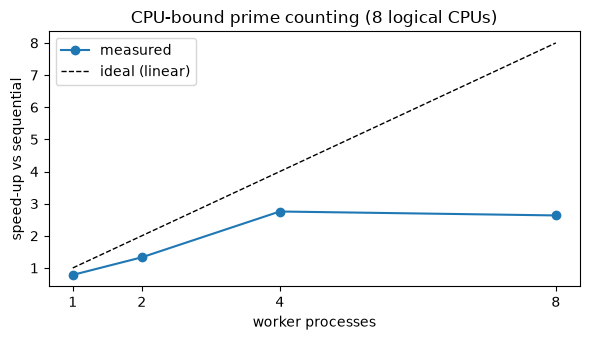

,workers,time (s),speed-up
0,sequential,4.297,1.000
1,1,5.482,0.784
2,2,3.230,1.331
3,4,1.559,2.756
4,8,1.632,2.634


In [13]:
LIMIT, N_CHUNKS = 600_000, 24
step = LIMIT // N_CHUNKS
chunks = [(i * step, (i + 1) * step) for i in range(N_CHUNKS)]

with Timer() as t_seq:
    total_seq = sum(W.count_primes(c) for c in chunks)          # sequential baseline

mp_rows = [{"workers": "sequential", "time (s)": t_seq.seconds, "speed-up": 1.0}]
for n_workers in [1, 2, 4, 8]:
    with SPAWN.Pool(n_workers) as pool:
        pool.map(W.slow_square, range(n_workers), chunksize=1)   # warm up: start every process first
        with Timer() as t_par:
            total_par = sum(pool.map(W.count_primes, chunks, chunksize=1))
    assert total_par == total_seq                               # same answer
    mp_rows.append({"workers": n_workers, "time (s)": t_par.seconds, "speed-up": t_seq.seconds / t_par.seconds})
mp_df = pd.DataFrame(mp_rows)
print(f"primes below {LIMIT:,}: {total_seq:,}")
fig, ax = plt.subplots(figsize=(6, 3.5))
ws = [1, 2, 4, 8]
ax.plot(ws, mp_df["speed-up"][1:], "o-", label="measured")
ax.plot(ws, ws, "k--", lw=1, label="ideal (linear)")
ax.set_xlabel("worker processes"); ax.set_ylabel("speed-up vs sequential")
ax.set_title(f"CPU-bound prime counting ({CPUS} logical CPUs)"); ax.legend(); ax.set_xticks(ws)
plt.tight_layout(); plt.show()
best = mp_df["speed-up"][1:].max()
assert best > 1.5
mp_df.round(3)

**What just happened?** The answer is identical for every configuration, and more processes made the CPU-bound job faster, unlike the threads in Section 3. The curve stays below the ideal line because of:
- **Amdahl's law**: if a fraction $s$ of the work is serial, the speed-up with $p$ workers is at most $\frac{1}{s + (1 - s)/p}$;
- overhead: sending tasks and results between processes, and load imbalance (bigger numbers take longer to test);
- other programs using the same cores. On a shared machine, the measured curve can flatten well before 8 workers. The exact numbers are in the table.

We started the pools *before* timing. Starting a `spawn` process costs tens to hundreds of milliseconds (a fresh interpreter plus imports), so pools should be **created once and reused**, not created per request.

### 5.2 Sharing data, and what pickling costs
Every argument sent to a worker process, and every result sent back, is **pickled** (serialised), copied through a pipe, and unpickled. For big arrays, that copy can cost more than the computation.

In [14]:
big = np.random.default_rng(0).random(5_000_000)              # 40 MB of float64 ("embeddings")
with Timer() as t_pk:
    blob = pickle.dumps(big, protocol=pickle.HIGHEST_PROTOCOL)
print(f"array: {big.nbytes / 1e6:.0f} MB, pickled: {len(blob) / 1e6:.0f} MB in {t_pk.seconds * 1e3:.0f} ms (one copy)")

with SPAWN.Pool(4) as pool:
    pool.map(W.slow_square, range(4), chunksize=1)            # warm-up
    with Timer() as t_copy:                                   # send the WHOLE array to each of 4 tasks
        sums_copy = pool.map(W.checksum, [big] * 4, chunksize=1)

    from multiprocessing import shared_memory
    shm = shared_memory.SharedMemory(create=True, size=big.nbytes)   # one shared buffer
    try:
        shared = np.ndarray(big.shape, dtype=big.dtype, buffer=shm.buf)
        shared[:] = big                                       # copy in once
        q = len(big) // 4
        jobs = [(shm.name, big.shape, big.dtype.str, i * q, (i + 1) * q) for i in range(4)]
        with Timer() as t_shm:                                # send only the NAME + slice bounds
            sums_shm = pool.starmap(W.checksum_shared, jobs, chunksize=1)
        del shared
    finally:
        shm.close(); shm.unlink()                             # always free shared memory

with Timer() as t_local:
    local_sum = float(big.sum())
assert math.isclose(sum(sums_shm), local_sum, rel_tol=1e-9) and math.isclose(sums_copy[0], local_sum)
pd.DataFrame([
    {"approach": "local big.sum() (no processes)", "time (s)": t_local.seconds},
    {"approach": "pickle whole array to 4 tasks", "time (s)": t_copy.seconds},
    {"approach": "shared memory, 4 slices", "time (s)": t_shm.seconds},
]).round(4)

array: 40 MB, pickled: 40 MB in 62 ms (one copy)


,approach,time (s)
0,local big.sum() (no processes),0.0110
1,pickle whole array to 4 tasks,2.2824
2,"shared memory, 4 slices",0.0302


**What just happened?** Summing 5 million numbers locally takes milliseconds. Sending the 40 MB array to 4 tasks meant pickling, piping and unpickling 160 MB, which was far slower than the sum itself, so parallelism made things *worse*. With `multiprocessing.shared_memory`, the workers attached to one buffer by **name** and only tiny tuples were sent. Rules of thumb:
- Send **small** things (file paths, IDs, index ranges) and let workers load the data themselves, or use shared memory or memory-mapped files (`np.memmap`, Arrow, Parquet).
- Make each task **coarse** (big chunks of work), so the per-task overhead is amortised. `chunksize=` in `Pool.map` helps.
- Load heavy objects, like a model, **once per worker** with an `initializer`:

In [15]:
with Timer() as t_init:
    with SPAWN.Pool(2, initializer=W.load_model) as pool:      # load_model runs once in each worker
        preds = pool.map(W.predict, range(8), chunksize=1)
print("predictions (worker pid hidden, value):", [v for _, v in preds])
print("worker processes that served predictions:", len({pid for pid, _ in preds}))
print("model loads: one per worker process (2), not one per prediction (8)")
print(f"pool start-up + 2 model loads + 8 predictions: {t_init.seconds:.2f} s")

predictions (worker pid hidden, value): [0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5]
worker processes that served predictions: 2
model loads: one per worker process (2), not one per prediction (8)
pool start-up + 2 model loads + 8 predictions: 0.75 s


## 6. `concurrent.futures`: one interface for threads and processes

*In plain English: hand jobs to a pool of helpers and collect the results as they finish.*

`concurrent.futures` gives a high-level **executor** API. You `submit()` a function and get back a **Future**, a placeholder for a result that will exist later. `ThreadPoolExecutor` and `ProcessPoolExecutor` have the same interface, so switching between them is a one-word change.

| | `ThreadPoolExecutor` | `ProcessPoolExecutor` |
|---|---|---|
| Good for | I/O-bound work, and C code that releases the GIL | CPU-bound pure Python |
| Default `max_workers` | `min(32, os.cpu_count() + 4)` | `os.cpu_count()` |
| Arguments | anything (shared memory) | must be picklable; functions must be importable |

- `executor.map(fn, items)` returns results **in input order**.
- `as_completed(futures)` yields futures **in completion order**, so you can show the fastest results first.
- `future.result(timeout=s)` raises `TimeoutError` if the result is not ready in time.
- `wait(futures, return_when=FIRST_COMPLETED)` returns as soon as any future finishes.

In [16]:
def fetch_doc(doc_id):
    latency = {0: 0.30, 1: 0.05, 2: 0.20, 3: 0.10, 4: 0.15}[doc_id]   # different "network" latencies
    time.sleep(latency)
    if doc_id == 3:
        raise ConnectionError(f"doc {doc_id}: 502 Bad Gateway")
    return f"doc {doc_id} ({latency:.2f}s)"

with ThreadPoolExecutor(max_workers=5) as ex:
    futures = {ex.submit(fetch_doc, i): i for i in range(5)}         # submitted in order 0..4
    order = []
    for fut in as_completed(futures):                                # arrive in completion order
        try:
            order.append(fut.result())
        except ConnectionError as e:
            order.append(f"FAILED: {e}")
print("completion order:"); [print("  ", o) for o in order]

with ThreadPoolExecutor(max_workers=3) as ex:            # 1 thread for the slow task + 2 for the replicas
    slow = ex.submit(time.sleep, 0.5)
    try:
        slow.result(timeout=0.1)                                     # do not wait more than 100 ms
    except FutureTimeout:
        print("timeout after 0.1 s; still running in the background?", slow.running())

    # hedged requests: ask two replicas, use whichever answers first
    replica = lambda name, lat: (time.sleep(lat), name)[1]
    done, pending = wait([ex.submit(replica, "replica-eu", 0.12), ex.submit(replica, "replica-us", 0.04)],
                         return_when=FIRST_COMPLETED)
    print("hedged request answered by:", next(iter(done)).result())

with ProcessPoolExecutor(max_workers=4, mp_context=SPAWN) as pex:   # same API, real processes
    counts = list(pex.map(W.count_primes, chunks[:8]))
print("process pool, primes per chunk:", counts)

completion order:
   doc 1 (0.05s)
   FAILED: doc 3: 502 Bad Gateway
   doc 4 (0.15s)
   doc 2 (0.20s)
   doc 0 (0.30s)
timeout after 0.1 s; still running in the background? True
hedged request answered by: replica-us


process pool, primes per chunk: [2762, 2371, 2260, 2199, 2142, 2114, 2068, 2068]


**What just happened?** The futures came back in **completion order** (doc 1 first, at 0.05 s), not in submission order, and the failure of doc 3 was re-raised by `fut.result()` where we could handle it. The timeout fired after 0.1 s. Note that the task was **still running**: a timeout stops your *waiting*, not the work. Python threads cannot be killed from outside, so long tasks should check a stop `Event` or have their own timeouts (for example `httpx.Client(timeout=...)`). The hedged request returned the faster replica's answer. Hedging is a standard trick against *tail latency*.

> ⚠️ **Common mistake:** forgetting to call `.result()` (or to check `.exception()`) on futures. An exception inside a task is stored in its future. If nobody asks, the error disappears silently.

## 7. `asyncio`

*In plain English: one very organised worker who never stands idle while waiting.*

### 7.1 Event loop, coroutines, tasks

**Intuition.** Threads are like several waiters, each assigned to one table, who stand idle while their customers decide. `asyncio` is one very efficient waiter who never stands still: they take an order, hand it to the kitchen, and *while it cooks* serve other tables, coming back when the food is ready.

**Definitions.**
- An **event loop** is a scheduler running in one thread. It keeps a list of tasks that are ready to run, and it watches sockets and timers for the ones that are waiting.
- A **coroutine** is a function defined with `async def`. Calling it does **not** run it: it returns a coroutine object.
- `await x` means "pause this coroutine until `x` is done, and let the loop run other things meanwhile". It can only be used inside `async def` (or at the top level of a notebook).
- A **task** wraps a coroutine and schedules it on the loop (`asyncio.create_task`), so it runs concurrently with other tasks.
- **Cooperative multitasking**: a task switch happens **only at an `await`**. Code between two `await`s runs without interruption, so there are no surprise switches as with threads, but one blocking call freezes *everything*.

> **Jupyter note:** Jupyter (ipykernel) already runs an event loop, so `asyncio.run(main())` fails in a notebook. Use **`await main()`** directly at the top level of a cell. In a normal `.py` script, it is the opposite: call `asyncio.run(main())` once, at the entry point.

In [17]:
async def fake_llm(prompt, latency=0.1):
    await asyncio.sleep(latency)              # non-blocking wait: other tasks run meanwhile
    return f"answer to {prompt!r}"

coro = fake_llm("hi")
print("calling a coroutine function returns:", type(coro).__name__, "(nothing has run yet)")
try:
    asyncio.run(coro)                         # the script way: does not work inside Jupyter
except RuntimeError as e:
    print("asyncio.run inside Jupyter ->", e)
finally:
    coro.close()                              # we never awaited it; close it to avoid a warning

loop = asyncio.get_running_loop()
print("Jupyter's running loop:", type(loop).__name__, "| running:", loop.is_running())
print(await fake_llm("top-level await works in notebooks"))

calling a coroutine function returns: coroutine (nothing has run yet)
asyncio.run inside Jupyter -> asyncio.run() cannot be called from a running event loop
Jupyter's running loop: _UnixSelectorEventLoop | running: True
answer to 'top-level await works in notebooks'


In [18]:
prompts = ["summarise", "translate", "classify"]
with Timer() as t_one_by_one:
    for p in prompts:
        await fake_llm(p, 0.2)                                    # awaited one after another
with Timer() as t_gather:
    answers = await asyncio.gather(*(fake_llm(p, 0.2) for p in prompts))   # all at once
print(f"one by one: {t_one_by_one.seconds:.2f} s | gather: {t_gather.seconds:.2f} s")
print(answers)                                                     # gather keeps the input order

with Timer() as t_tasks:
    task = asyncio.create_task(fake_llm("background", 0.2))       # starts running right away
    await asyncio.sleep(0.15)                                     # meanwhile, do other work
    print("task done yet?", task.done())
    result = await task
print(result, f"(total {t_tasks.seconds:.2f} s)")

one by one: 0.60 s | gather: 0.20 s
["answer to 'summarise'", "answer to 'translate'", "answer to 'classify'"]
task done yet? False
answer to 'background' (total 0.20 s)


**What just happened?** Awaiting the three calls one by one took about 0.6 s. `gather` ran them **concurrently** in about 0.2 s, the time of the slowest one, and returned the results in input order. `create_task` started a coroutine in the background. While we slept for 0.15 s it was still running; once we awaited it, it finished at about 0.2 s in total, not 0.35 s.

### 7.2 Timeouts and cancellation

In [19]:
try:
    await asyncio.wait_for(fake_llm("long essay", latency=2.0), timeout=0.1)
except TimeoutError:                                    # asyncio.TimeoutError is TimeoutError since 3.11
    print("wait_for: gave up after 0.1 s (the inner task was cancelled)")

try:
    async with asyncio.timeout(0.1):                    # Python 3.11+: a timeout for a whole block
        await fake_llm("step 1", 0.05)
        await fake_llm("step 2", 0.05)
        await fake_llm("step 3", 0.05)                  # the block's budget runs out here
except TimeoutError:
    print("asyncio.timeout: the 3-step block exceeded its 0.1 s budget")

log = []
async def stream_answer():
    try:
        for i in range(100):
            await asyncio.sleep(0.02)                   # CancelledError is raised at an await
            log.append(f"token{i}")
    except asyncio.CancelledError:
        log.append("cancelled -> closing the HTTP stream")   # clean up ...
        raise                                           # ... and ALWAYS re-raise
    finally:
        log.append("finally ran")

t = asyncio.create_task(stream_answer())
await asyncio.sleep(0.07)                               # user clicks "stop generating"
t.cancel()
try:
    await t
except asyncio.CancelledError:
    pass
print("task cancelled?", t.cancelled(), "| log:", log)

wait_for: gave up after 0.1 s (the inner task was cancelled)
asyncio.timeout: the 3-step block exceeded its 0.1 s budget
task cancelled? True | log: ['token0', 'token1', 'token2', 'cancelled -> closing the HTTP stream', 'finally ran']


**What just happened?** `wait_for` and `asyncio.timeout` both raised `TimeoutError` and **cancelled** the work inside. Cancelling a task injects `CancelledError` at its current `await`. The coroutine got a chance to clean up (close the stream) in `except`/`finally`, and then it had to **re-raise**. Swallowing `CancelledError` breaks timeouts and shutdown. This is exactly how a "stop generating" button works in a streaming chat UI.

### 7.3 Errors: `gather(return_exceptions=True)` vs `TaskGroup`

In [20]:
async def flaky(i):
    await asyncio.sleep(0.01 * i)
    if i in (2, 4):
        raise ValueError(f"call {i} returned invalid JSON")
    return i

results = await asyncio.gather(*(flaky(i) for i in range(6)), return_exceptions=True)
print("gather(return_exceptions=True):", results)

try:
    async with asyncio.TaskGroup() as tg:                  # Python 3.11+: structured concurrency
        tasks = [tg.create_task(flaky(i)) for i in range(6)]
except* ValueError as eg:                                  # except* handles an ExceptionGroup
    print(f"TaskGroup raised an ExceptionGroup with {len(eg.exceptions)} error(s):",
          [str(e) for e in eg.exceptions])
    print("the other tasks were cancelled when the first one failed:",
          [t.cancelled() for t in tasks])

gather(return_exceptions=True): [0, 1, ValueError('call 2 returned invalid JSON'), 3, ValueError('call 4 returned invalid JSON'), 5]
TaskGroup raised an ExceptionGroup with 1 error(s): ['call 2 returned invalid JSON']
the other tasks were cancelled when the first one failed: [False, False, False, True, True, True]


**What just happened?** `gather(return_exceptions=True)` returned errors *as values* next to the successful results, which is good when you want partial results. `TaskGroup` uses **structured concurrency**: when one task fails, it **cancels the siblings** that are still running, waits for them all, and raises an `ExceptionGroup`. You handle that with `except*`. Here only the first error (call 2) was raised; calls 3, 4 and 5 were cancelled before they finished, so call 4 never got to fail. No task outlives the `async with` block, and that is why `TaskGroup` is the recommended default in modern code.

### 7.4 Async context managers and async generators

In [21]:
from contextlib import asynccontextmanager

class FakeLLMClient:
    """Like httpx.AsyncClient: open a connection pool on enter, close it on exit."""
    async def __aenter__(self):
        await asyncio.sleep(0.01)                       # "open connections"
        self.open = True
        return self
    async def __aexit__(self, exc_type, exc, tb):
        await asyncio.sleep(0.01)                       # "close connections", even after errors
        self.open = False
        return False                                    # don't swallow exceptions
    async def stream(self, prompt):                     # an ASYNC GENERATOR: async def + yield
        for word in f"Sure! Here is a short answer about {prompt}.".split():
            await asyncio.sleep(0.03)                   # each token arrives over the network
            yield word

@asynccontextmanager
async def span(name, timings):                          # a tiny tracing span
    t0 = time.perf_counter()
    try:
        yield
    finally:
        timings[name] = round(time.perf_counter() - t0, 3)

timings, tokens = {}, []
async with FakeLLMClient() as client, span("generation", timings):
    t_start = time.perf_counter()
    async for tok in client.stream("asyncio"):          # consume the async generator
        if not tokens:                                  # first token: measure time-to-first-token
            timings["time_to_first_token"] = round(time.perf_counter() - t_start, 3)
        tokens.append(tok)
print(" ".join(tokens))
print("client still open?", client.open, "| span timings:", timings)

Sure! Here is a short answer about asyncio.
client still open? False | span timings: {'time_to_first_token': 0.032, 'generation': 0.244}


**What just happened?** `async with` called `__aenter__` and `__aexit__`, which can themselves `await`, for example to open and close network connections. `async for` consumed an **async generator** that yielded tokens as they "arrived". The first token came after about 0.03 s, while the whole answer took several times longer. That gap is why chat UIs stream: users see the answer start right away. This is the shape of every streaming LLM SDK. The `@asynccontextmanager` decorator turned a generator into a reusable timing span.

### 7.5 `asyncio.Queue` workers and `Semaphore` limits

In [22]:
async def worker(name, q, done):
    while True:
        prompt = await q.get()                         # wait for work
        try:
            done.append((name, await fake_llm(prompt, 0.05)))
        finally:
            q.task_done()

q, done = asyncio.Queue(), []
for i in range(12):
    q.put_nowait(f"prompt-{i}")
with Timer() as t_q:
    workers = [asyncio.create_task(worker(f"w{i}", q, done)) for i in range(3)]
    await q.join()                                     # until every item is task_done()
    for w in workers:
        w.cancel()                                     # workers loop forever: cancel them
    await asyncio.gather(*workers, return_exceptions=True)
print(f"12 prompts, 3 async workers: {t_q.seconds:.2f} s (12 x 0.05 / 3 = 0.20 s ideal)")

in_flight = peak_flight = 0
limit = asyncio.Semaphore(5)                           # at most 5 concurrent API calls
async def limited_call(i):
    global in_flight, peak_flight
    async with limit:
        in_flight += 1; peak_flight = max(peak_flight, in_flight)   # safe: no await in between
        try:
            return await fake_llm(i, 0.05)
        finally:
            in_flight -= 1
with Timer() as t_lim:
    await asyncio.gather(*(limited_call(i) for i in range(50)))
print(f"50 calls with Semaphore(5): peak in flight = {peak_flight}, time = {t_lim.seconds:.2f} s (ideal 0.50 s)")
assert peak_flight == 5

12 prompts, 3 async workers: 0.21 s (12 x 0.05 / 3 = 0.20 s ideal)


50 calls with Semaphore(5): peak in flight = 5, time = 0.52 s (ideal 0.50 s)


**What just happened?** Three async workers shared 12 queued prompts and finished in about the ideal 0.2 s. The `asyncio.Semaphore(5)` capped concurrency at exactly 5 in-flight calls, which is how you respect a provider's concurrency limit or avoid overloading your own vector database. Notice that `in_flight += 1` needed **no lock**: asyncio only switches tasks at an `await`, so a line without `await` cannot be interrupted by another task.

### 7.6 Simulation: 100 LLM API calls, sequential vs threads vs asyncio

A realistic load: 100 calls with random latency between 20 and 120 ms, and **15% transient failures** (think HTTP 429 or 503). Each call's latency and failure are **seeded by request id and attempt number**, so every strategy faces *exactly* the same calls.

In [23]:
N_CALLS = 100

class TransientAPIError(Exception):
    """e.g. 429 Too Many Requests / 503 Service Unavailable: worth retrying."""

def call_plan(i, attempt):
    r = random.Random(i * 1000 + attempt)             # deterministic per (request, attempt)
    return r.uniform(0.02, 0.12), r.random() < 0.15   # (latency in s, does it fail?)

def llm_sync(i, attempt=0):
    latency, fails = call_plan(i, attempt)
    time.sleep(latency)                               # blocking wait
    if fails:
        raise TransientAPIError(f"503 on request {i}")
    return f"answer-{i}"

async def llm_async(i, attempt=0):
    latency, fails = call_plan(i, attempt)
    await asyncio.sleep(latency)                      # non-blocking wait
    if fails:
        raise TransientAPIError(f"503 on request {i}")
    return f"answer-{i}"

def record(timeline, i, t0, fn):
    start = time.perf_counter() - t0
    try:
        fn(); ok = True
    except TransientAPIError:
        ok = False
    timeline.append((i, start, time.perf_counter() - t0, ok))

async def record_async(timeline, i, t0, coro_fn, sem=None):
    async def body():
        start = time.perf_counter() - t0
        try:
            await coro_fn(); ok = True
        except TransientAPIError:
            ok = False
        timeline.append((i, start, time.perf_counter() - t0, ok))
    if sem is None:
        return await body()
    async with sem:
        return await body()

timelines = {}
t0 = time.perf_counter(); tl = []
for i in range(N_CALLS):
    record(tl, i, t0, lambda i=i: llm_sync(i))
timelines["sequential"] = tl

t0 = time.perf_counter(); tl = []
with ThreadPoolExecutor(max_workers=20) as ex:
    list(ex.map(lambda i: record(tl, i, t0, lambda: llm_sync(i)), range(N_CALLS)))
timelines["20 threads"] = tl

t0 = time.perf_counter(); tl = []; sem = asyncio.Semaphore(20)
await asyncio.gather(*(record_async(tl, i, t0, lambda i=i: llm_async(i), sem) for i in range(N_CALLS)))
timelines["asyncio, limit 20"] = tl

t0 = time.perf_counter(); tl = []
await asyncio.gather(*(record_async(tl, i, t0, lambda i=i: llm_async(i)) for i in range(N_CALLS)))
timelines["asyncio, no limit"] = tl

sim = pd.DataFrame([{"strategy": k, "wall time (s)": max(e for _, _, e, _ in v),
                     "succeeded": sum(ok for *_, ok in v), "failed": sum(not ok for *_, ok in v)}
                    for k, v in timelines.items()])
sim["speed-up vs sequential"] = sim["wall time (s)"][0] / sim["wall time (s)"]
assert (sim["failed"] == 8).all() and (sim["speed-up vs sequential"][1:3] > 10).all()
sim.round(3)

,strategy,wall time (s),succeeded,failed,speed-up vs sequential
0,sequential,6.389,92,8,1.000
1,20 threads,0.416,92,8,15.359
2,"asyncio, limit 20",0.394,92,8,16.216
3,"asyncio, no limit",0.125,92,8,51.020


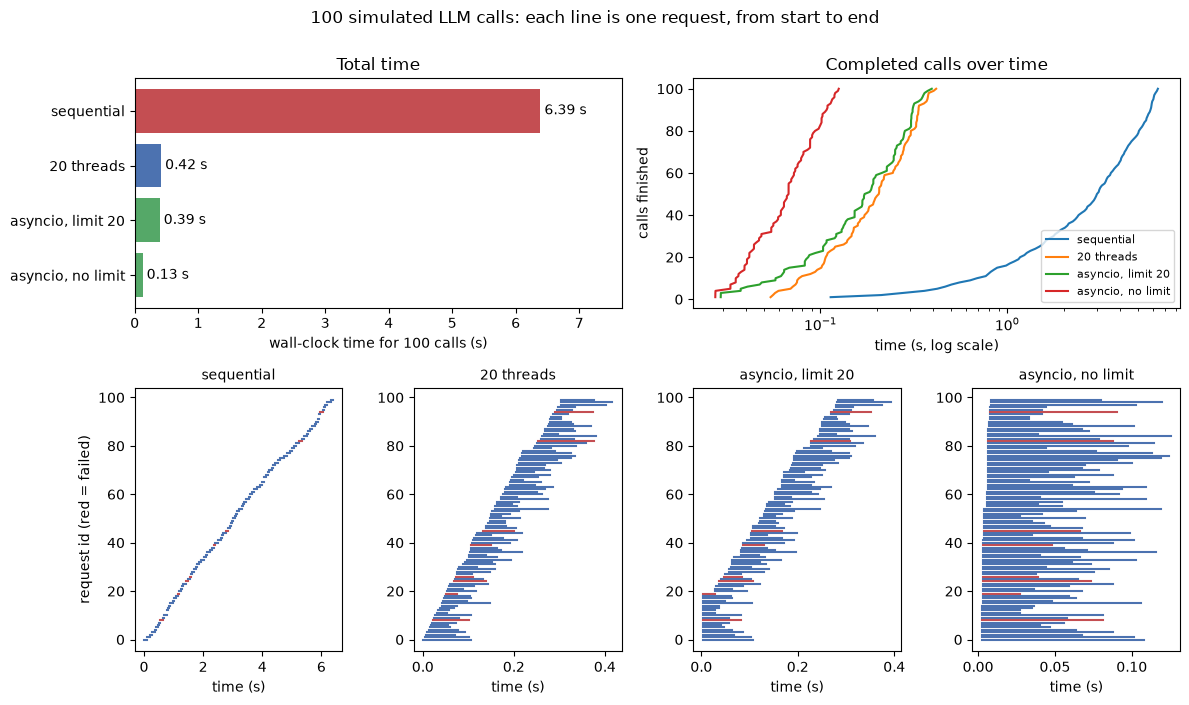

In [24]:
fig = plt.figure(figsize=(12, 7))
gs = fig.add_gridspec(2, 4, height_ratios=[1, 1.15])
ax_bar = fig.add_subplot(gs[0, :2])
ax_bar.barh(sim["strategy"][::-1], sim["wall time (s)"][::-1], color=["#55A868", "#55A868", "#4C72B0", "#C44E52"])
for y, v in enumerate(sim["wall time (s)"][::-1]):
    ax_bar.text(v, y, f" {v:.2f} s", va="center")
ax_bar.set_xlabel("wall-clock time for 100 calls (s)"); ax_bar.set_title("Total time")
ax_bar.set_xlim(0, sim["wall time (s)"].max() * 1.2)
ax_c = fig.add_subplot(gs[0, 2:])
for name, tl in timelines.items():
    ends = sorted(e for _, _, e, _ in tl)
    ax_c.plot(ends, range(1, len(ends) + 1), label=name)
ax_c.set_xscale("log"); ax_c.set_xlabel("time (s, log scale)"); ax_c.set_ylabel("calls finished")
ax_c.set_title("Completed calls over time"); ax_c.legend(fontsize=8)
for k, (name, tl) in enumerate(timelines.items()):
    ax = fig.add_subplot(gs[1, k])
    for i, s, e, ok in tl:
        ax.plot([s, e], [i, i], color="#4C72B0" if ok else "#C44E52", lw=1.5)
    ax.set_title(name, fontsize=10); ax.set_xlabel("time (s)")
    if k == 0: ax.set_ylabel("request id (red = failed)")
fig.suptitle("100 simulated LLM calls: each line is one request, from start to end", y=1.0)
plt.tight_layout(); plt.show()

**What just happened?** All four strategies saw the same latencies and the same 8 failures (92 successes).
- **Sequential**: the timeline is a staircase. Each call starts only when the previous one ends, so the total is the *sum* of all latencies (about 6.4 s).
- **20 threads** and **asyncio with a limit of 20**: about 20 calls in flight at any time, so more than 10× faster (a bit below the ideal 20×, because each "wave" waits for its slower calls). Their timelines look the same, because for I/O-bound work both are *concurrency* and both overlap the waiting.
- **asyncio with no limit**: all 100 start at once, so the total is about the *slowest single* call. Fast, but a real provider would answer with HTTP 429 (rate limited). This is why we need limits (Section 7.8).

Why prefer asyncio for many API calls? One thread can hold thousands of concurrent waits with tiny memory per task, and all the waiting is explicit. Threads work too, and are fine for tens of calls with synchronous libraries.

### 7.7 Retries with exponential backoff and jitter

Transient errors (timeouts, 429, 503) should be **retried**. Permanent errors (400 Bad Request, 401 Unauthorized) should **not**: retrying cannot fix a bad request. Retry *politely*:
- **Exponential backoff**: wait `base × 2^attempt`, with a **cap**. Each retry waits longer, which gives an overloaded service time to recover.
- **Jitter**: randomise the wait. Without it, all the clients that failed together retry *together*, and the spikes keep hammering the server (the **thundering herd**). "Full jitter" waits `uniform(0, min(cap, base × 2^attempt))`.
- Honour a `Retry-After` header when the server sends one, and set a **maximum number of attempts** (or a total deadline).

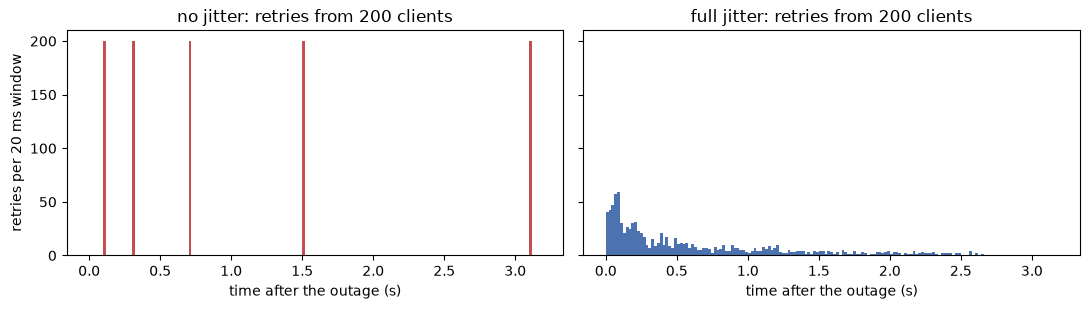

busiest 20 ms window: 200 retries without jitter vs 59 with full jitter


In [25]:
def backoff_delay(attempt, base=0.1, cap=2.0, jitter=True, rng=random):
    ceiling = min(cap, base * 2 ** attempt)              # exponential, capped
    return rng.uniform(0, ceiling) if jitter else ceiling

# 200 clients all fail at t=0 and retry up to 5 times: when do their retries hit the server?
rng_j = random.Random(1)
retry_times = {"no jitter": [], "full jitter": []}
for label, jit in [("no jitter", False), ("full jitter", True)]:
    for client in range(200):
        t = 0.0
        for attempt in range(5):
            t += backoff_delay(attempt, jitter=jit, rng=rng_j)
            retry_times[label].append(t)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, (label, ts) in zip(axes, retry_times.items()):
    ax.hist(ts, bins=np.arange(0, 3.2, 0.02), color="#C44E52" if label == "no jitter" else "#4C72B0")
    ax.set_title(f"{label}: retries from 200 clients"); ax.set_xlabel("time after the outage (s)")
axes[0].set_ylabel("retries per 20 ms window")
plt.tight_layout(); plt.show()
peak_no = np.histogram(retry_times["no jitter"], bins=np.arange(0, 3.2, 0.02))[0].max()
peak_j = np.histogram(retry_times["full jitter"], bins=np.arange(0, 3.2, 0.02))[0].max()
print(f"busiest 20 ms window: {peak_no} retries without jitter vs {peak_j} with full jitter")

In [26]:
async def call_with_retries(i, max_attempts=4, base=0.02, cap=0.5, rng=None):
    rng = rng or random.Random(i)
    for attempt in range(max_attempts):
        try:
            return await llm_async(i, attempt), attempt + 1           # (answer, attempts used)
        except TransientAPIError:
            if attempt == max_attempts - 1:
                raise                                                 # give up: let the caller decide
            await asyncio.sleep(backoff_delay(attempt, base, cap, rng=rng))

sem = asyncio.Semaphore(20)
async def limited_retry(i):
    async with sem:
        try:
            return await call_with_retries(i)
        except TransientAPIError:
            return None, 4

with Timer() as t_retry:
    out = await asyncio.gather(*(limited_retry(i) for i in range(N_CALLS)))
attempts = pd.Series([a for _, a in out]).value_counts().sort_index()
ok = sum(ans is not None for ans, _ in out)
print(f"with retries: {ok}/{N_CALLS} succeeded in {t_retry.seconds:.2f} s")
print("attempts needed per request:", attempts.to_dict())

with retries: 100/100 succeeded in 0.45 s
attempts needed per request: {1: 92, 2: 8}


**What just happened?** Without jitter, every client retries at exactly the same moments (0.1 s, 0.3 s, 0.7 s, ...), and each spike contains all 200 retries. With full jitter, the same 1,000 retries are spread out, and the busiest 20 ms window holds 59 instead of 200. With retries, all 100 calls succeeded, compared with 92 without retries: 92 needed one attempt and the 8 that failed first time succeeded on their second attempt. The cost was only a little extra time, because backoffs overlap with the other requests.

In production, use a tested library: **tenacity** (`@retry(wait=wait_random_exponential(...), stop=stop_after_attempt(4))`), or the retry options built into the official LLM SDKs and `httpx` transports. Retry only **idempotent** operations, or use idempotency keys, so that a retried "charge the card" does not charge twice.

### 7.8 A token-bucket rate limiter

Providers limit **requests per minute** (RPM) and **tokens per minute** (TPM). A **token bucket** is the classic algorithm:
- a bucket holds at most `capacity` tokens and refills continuously at `rate` tokens per second;
- each request must take `cost` tokens (1 per request for RPM, or the prompt's token count for TPM). If there are not enough, it **waits** until the bucket has refilled.

`capacity` allows short **bursts**, and `rate` bounds the **long-run average**: over any period $t$, at most `capacity + rate × t` tokens can be spent.

50 requests, burst 10, rate 25/s -> last grant at 1.60 s (theory 1.60 s)


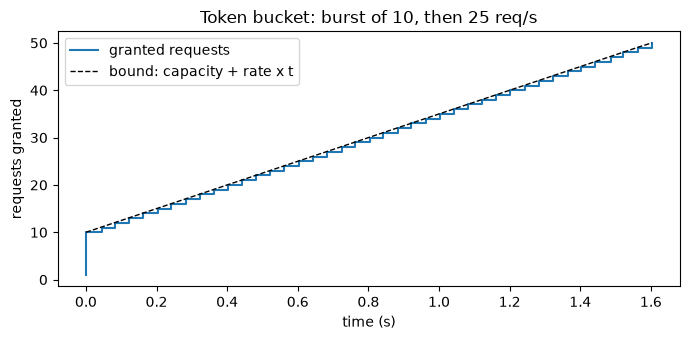

In [27]:
class TokenBucket:
    """Async token bucket: at most `capacity` burst, `rate` tokens/second on average."""
    def __init__(self, rate, capacity):
        self.rate, self.capacity = float(rate), float(capacity)
        self.tokens = float(capacity)                      # start full
        self.updated = time.monotonic()
        self._lock = asyncio.Lock()                        # waiters are served one at a time (FIFO)

    def _refill(self):
        now = time.monotonic()
        self.tokens = min(self.capacity, self.tokens + (now - self.updated) * self.rate)
        self.updated = now

    async def acquire(self, cost=1.0):
        if cost > self.capacity:
            raise ValueError("cost larger than the bucket can ever hold")
        async with self._lock:
            while True:
                self._refill()
                if self.tokens >= cost:
                    self.tokens -= cost
                    return
                await asyncio.sleep((cost - self.tokens) / self.rate)   # sleep exactly until enough refills

RATE, CAPACITY, N_REQ = 25, 10, 50
bucket = TokenBucket(rate=RATE, capacity=CAPACITY)
grants = []
async def rate_limited_request(i, t0):
    await bucket.acquire()
    grants.append(time.perf_counter() - t0)

t0 = time.perf_counter()
await asyncio.gather(*(rate_limited_request(i, t0) for i in range(N_REQ)))
grants.sort()
theory = (N_REQ - CAPACITY) / RATE
print(f"{N_REQ} requests, burst {CAPACITY}, rate {RATE}/s -> last grant at {grants[-1]:.2f} s (theory {theory:.2f} s)")
assert abs(grants[-1] - theory) < 0.25
for k, t in enumerate(grants, start=1):                     # never above the bound (small timer slack)
    assert k <= CAPACITY + RATE * t + 1

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.step(grants, range(1, N_REQ + 1), where="post", label="granted requests")
ts = np.linspace(0, grants[-1], 50)
ax.plot(ts, np.minimum(N_REQ, CAPACITY + RATE * ts), "k--", lw=1, label="bound: capacity + rate x t")
ax.set_xlabel("time (s)"); ax.set_ylabel("requests granted"); ax.set_title("Token bucket: burst of 10, then 25 req/s")
ax.legend(); plt.tight_layout(); plt.show()

**What just happened?** The first 10 requests went through immediately (the burst), and the rest were spaced at 25 per second. The last grant arrived at the predicted $(50 - 10) / 25 = 1.6$ s, and the step curve never crossed the bound line. For TPM limits, call `acquire(cost=n_tokens)` on a second bucket; real clients hold one bucket for requests and one for tokens. Related algorithms: the *leaky bucket* (smooth output rate) and *sliding-window counters* (common in API gateways). For several processes or machines, the bucket must live in a shared store such as Redis.

## 8. Batching requests and backpressure

*In plain English: send work in bundles, and don't let a fast sender bury a slow receiver.*

### 8.1 Micro-batching
Embedding APIs and GPU inference have a large **fixed cost per call** and a small cost per item. A **micro-batcher** collects individual requests for a short time (up to `max_batch` items or `max_wait` seconds, whichever comes first), sends **one** batched call, and hands each caller its own result. Inference servers (Triton, vLLM, TGI, TorchServe) do this as *dynamic batching* or *continuous batching*.

In [28]:
class FakeEmbeddingAPI:
    def __init__(self):
        self.calls = 0
    async def embed(self, texts):                       # cost: 30 ms per call + 1 ms per text
        self.calls += 1
        await asyncio.sleep(0.030 + 0.001 * len(texts))
        return [len(t) for t in texts]                  # pretend "embedding"

class MicroBatcher:
    def __init__(self, api, max_batch=16, max_wait=0.01):
        self.api, self.max_batch, self.max_wait = api, max_batch, max_wait
        self.q = asyncio.Queue()
        self.sizes = []
    async def submit(self, text):
        fut = asyncio.get_running_loop().create_future()   # where our result will appear
        await self.q.put((text, fut))
        return await fut
    async def run(self):
        loop = asyncio.get_running_loop()
        while True:
            batch = [await self.q.get()]                   # wait for the first item
            deadline = loop.time() + self.max_wait
            while len(batch) < self.max_batch:             # then collect more until full or deadline
                remaining = deadline - loop.time()
                if remaining <= 0:
                    break
                try:
                    batch.append(await asyncio.wait_for(self.q.get(), remaining))
                except TimeoutError:
                    break
            self.sizes.append(len(batch))
            vectors = await self.api.embed([text for text, _ in batch])
            for (_, fut), vec in zip(batch, vectors):
                fut.set_result(vec)                         # wake each caller with its own result

texts = [f"chunk {i} " * (i % 5 + 1) for i in range(64)]

api1, sem4 = FakeEmbeddingAPI(), asyncio.Semaphore(4)
async def one_by_one(t):
    async with sem4:
        return (await api1.embed([t]))[0]
with Timer() as t_single:
    single = await asyncio.gather(*(one_by_one(t) for t in texts))

api2 = FakeEmbeddingAPI(); batcher = MicroBatcher(api2)
runner = asyncio.create_task(batcher.run())
with Timer() as t_batched:
    batched = await asyncio.gather(*(batcher.submit(t) for t in texts))
runner.cancel()
await asyncio.gather(runner, return_exceptions=True)
assert single == batched == [len(t) for t in texts]
assert api2.calls == 4 and t_single.seconds > 2 * t_batched.seconds
pd.DataFrame([{"approach": "1 text per call (4 concurrent)", "API calls": api1.calls, "time (s)": t_single.seconds},
              {"approach": "micro-batched (max 16 / 10 ms)", "API calls": api2.calls, "time (s)": t_batched.seconds}]).round(3)

,approach,API calls,time (s)
0,1 text per call (4 concurrent),64,0.519
1,micro-batched (max 16 / 10 ms),4,0.191


**What just happened?** The 64 callers each awaited their *own* result, and the answers were identical either way. The batcher, however, made **4 API calls (batches of 16) instead of 64**, and finished more than twice as fast. Batching trades a few milliseconds of extra latency (`max_wait`) for much higher throughput and lower cost.

### 8.2 Backpressure
**Backpressure** means a slow consumer *pushes back* on a fast producer, so that work cannot pile up without limit. Without it, the queue (and memory) grows until the process crashes, and latency grows for every request in the queue. The simplest mechanism is a **bounded queue**: `await q.put(x)` *waits* while the queue is full.

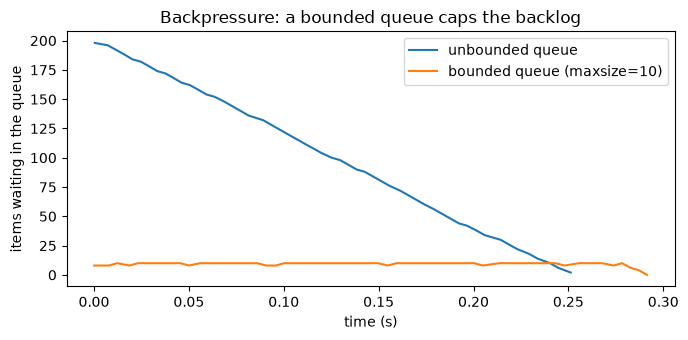

,queue,max items waiting,producer finished at (s),all done at (s)
0,unbounded queue,198,0.000,0.254
1,bounded queue (maxsize=10),10,0.276,0.292


In [29]:
async def pipeline(maxsize, n_items=200):
    q = asyncio.Queue(maxsize=maxsize)                 # maxsize=0 means unbounded
    loop = asyncio.get_running_loop(); t0 = loop.time()
    sizes, producer_done = [], {}
    async def producer():
        for i in range(n_items):
            await q.put(i)                             # waits when the queue is full -> backpressure
        producer_done["t"] = loop.time() - t0
    async def consumer():
        while True:
            await q.get(); await asyncio.sleep(0.002); q.task_done()   # slow: ~2 ms per item
    async def monitor():
        while True:
            sizes.append((loop.time() - t0, q.qsize())); await asyncio.sleep(0.004)
    tasks = [asyncio.create_task(c()) for c in (consumer, consumer, monitor)]
    await producer(); await q.join()
    for t in tasks: t.cancel()
    await asyncio.gather(*tasks, return_exceptions=True)
    return sizes, producer_done["t"], loop.time() - t0

fig, ax = plt.subplots(figsize=(7, 3.5))
bp_rows = []
for label, maxsize in [("unbounded queue", 0), ("bounded queue (maxsize=10)", 10)]:
    sizes, t_prod, t_total = await pipeline(maxsize)
    ax.plot([t for t, _ in sizes], [s for _, s in sizes], label=label)
    bp_rows.append({"queue": label, "max items waiting": max(s for _, s in sizes),
                    "producer finished at (s)": t_prod, "all done at (s)": t_total})
ax.set_xlabel("time (s)"); ax.set_ylabel("items waiting in the queue"); ax.legend()
ax.set_title("Backpressure: a bounded queue caps the backlog"); plt.tight_layout(); plt.show()
bp = pd.DataFrame(bp_rows)
assert bp["max items waiting"][1] <= 10 < bp["max items waiting"][0]
bp.round(3)

**What just happened?** With an unbounded queue, the producer "finished" almost instantly by dumping all 200 items into memory. The backlog peaked near 200 and then drained slowly. With `maxsize=10`, the backlog never exceeded 10. The producer was slowed down to the consumers' pace and finished only near the end, yet the total time was about the same. Backpressure does not make the system slower. It makes it **bounded**: memory and per-item waiting time stay capped.

At the edge of a web service, backpressure is often **load shedding**: reject early with HTTP 429 or 503 when the queue is full, rather than accepting work that will time out anyway.

## 9. Common pitfalls

*In plain English: the handful of mistakes that make concurrent programs slow, stuck or wrong.*

### 9.1 A blocking call inside async code freezes everything
An event loop runs on **one** thread. A blocking call (`time.sleep`, `requests.get`, a slow pure-Python computation, synchronous file or DB I/O) inside a coroutine stops *every* task until it returns. We measure it with a heartbeat task that should tick every 10 ms.

In [30]:
async def heartbeat(stop, gaps):
    last = time.perf_counter()
    while not stop.is_set():
        await asyncio.sleep(0.01)                      # should wake up every ~10 ms
        now = time.perf_counter(); gaps.append(now - last); last = now

async def blocking_handler():
    time.sleep(0.3)                                    # BAD: blocks the event loop thread

async def fixed_handler():
    await asyncio.to_thread(time.sleep, 0.3)           # GOOD: blocking work runs in a thread

for handler in (blocking_handler, fixed_handler):
    stop, gaps = asyncio.Event(), []
    hb = asyncio.create_task(heartbeat(stop, gaps))
    await asyncio.sleep(0.03)                          # let the heartbeat run first
    await handler()
    stop.set(); await hb
    print(f"{handler.__name__:17s}: longest heartbeat gap = {max(gaps) * 1000:.0f} ms (expected ~10 ms)")

blocking_handler : longest heartbeat gap = 320 ms (expected ~10 ms)


fixed_handler    : longest heartbeat gap = 17 ms (expected ~10 ms)


In [31]:
async def forgot_await():
    fake_llm("oops")                                   # BUG: creates a coroutine and never runs it
    return "done"

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    await forgot_await()
    gc.collect()                                       # the warning fires when the coroutine is destroyed
print("warning:", [f"{w.category.__name__}: {w.message}" for w in caught][:1])

n = 1000
with Timer() as t_threads:
    ths = [threading.Thread(target=time.sleep, args=(0.05,)) for _ in range(n)]
    for t in ths: t.start()
    for t in ths: t.join()
with Timer() as t_tasks:
    await asyncio.gather(*(asyncio.sleep(0.05) for _ in range(n)))
print(f"{n} concurrent waits: threads {t_threads.seconds:.2f} s vs asyncio tasks {t_tasks.seconds:.2f} s")
print("ThreadPoolExecutor default max_workers here:", min(32, CPUS + 4))

1000 concurrent waits: threads 1.91 s vs asyncio tasks 0.11 s
ThreadPoolExecutor default max_workers here: 12


**What just happened?**
- The blocking handler froze the heartbeat for about 300 ms: every other request on that server would have stalled too. `asyncio.to_thread` moved the blocking call to a worker thread, and the heartbeat kept ticking at about 10 ms.
- Forgetting `await` does nothing except produce a `RuntimeWarning: coroutine ... was never awaited`. Treat that warning as an error.
- 1,000 OS threads worked, but each one has its own stack (8 MB of reserved virtual memory by default on Linux) and costs time to create and switch between. 1,000 asyncio tasks cost a few KB each. Tens of thousands of threads will exhaust memory or OS limits. Prefer a **bounded pool** (`ThreadPoolExecutor(max_workers=...)`) over one thread per request.

| Pitfall | Symptom | Fix |
|---|---|---|
| blocking call in `async def` (`time.sleep`, `requests`, heavy CPU) | the whole server stalls; latency spikes | async libraries (`httpx.AsyncClient`, `asyncpg`, `aiofiles`), `asyncio.to_thread`, `loop.run_in_executor(process_pool, ...)` |
| forgetting `await` | nothing happens, plus a `RuntimeWarning` | linters (Ruff, mypy), `PYTHONASYNCIODEBUG=1` |
| fire-and-forget `create_task` without keeping a reference | the task may be garbage-collected mid-way; errors lost | keep tasks in a set, or use `TaskGroup` |
| swallowing `CancelledError` | timeouts and shutdown hang | always re-raise it |
| unlimited concurrency | 429s, out-of-memory, overloaded DB | `Semaphore`, connection-pool limits, token buckets |
| too many threads | memory blow-up, thrashing | bounded pools; asyncio for massive I/O |
| shared state across threads without a lock | lost updates, corrupted dicts | `Lock`, `queue.Queue`, immutable data |
| creating a process pool per request | seconds of overhead | create pools once at start-up |
| pickling huge arguments | parallel version slower than serial | pass paths or IDs, shared memory, coarse tasks |

## 10. When to use what

| Workload | Use | Why |
|---|---|---|
| Many network calls (LLM APIs, HTTP, vector DB, async DB drivers) | **asyncio** + semaphores / rate limiters | thousands of concurrent waits in one thread; explicit control |
| A few blocking I/O calls, or synchronous-only libraries | **`ThreadPoolExecutor`** | the GIL is released while waiting; minimal code change |
| CPU-heavy **pure Python** (parsing, feature engineering) | **`ProcessPoolExecutor`** / `multiprocessing` (or a free-threaded build) | sidesteps the GIL; real parallelism |
| CPU-heavy **numeric** code | **vectorise first** (NumPy / PyTorch use native threads internally) | releases the GIL; often 10–100× before any parallelism |
| Training-data loading and augmentation | `torch.utils.data.DataLoader(num_workers > 0)` | worker processes keep the GPU fed |
| Async web server that also does CPU work | asyncio + `run_in_executor(ProcessPoolExecutor)` | keeps the event loop responsive |
| Beyond one machine | Ray, Dask, Celery / RQ, Spark | distributed scheduling, retries, clusters |

> 🎓 **Exam / interview tip:** first classify the workload as CPU-bound or I/O-bound, by measuring CPU time against wall time. Then pick processes for CPU-bound work and threads or asyncio for I/O-bound work. Mention the GIL, and say how you would limit concurrency and handle failures (timeouts, retries with backoff and jitter, rate limits).

## 🔗 How this connects to modern AI

| Concept here | In real AI systems |
|---|---|
| asyncio + semaphores + retries + token buckets | every LLM SDK (async clients, built-in retries); batch evaluation of thousands of prompts; agents calling tools in parallel ([MCP and tools](../10_Agents/05_mcp_and_tools.ipynb)) |
| async generators, cancellation | streaming tokens to a chat UI; a "stop generating" button |
| async web frameworks | `async def` endpoints in FastAPI ([Advanced FastAPI](../12_FastAPI/02_advanced_fastapi.ipynb), [ML serving](../12_FastAPI/03_ml_serving_with_fastapi.ipynb)) |
| micro-batching, backpressure | dynamic / continuous batching in vLLM, TGI and Triton; queue-based ingestion for RAG ([Inference optimisation](../08_LLM/13_inference_optimization.ipynb)) |
| processes, shared memory, initializers | `DataLoader` workers; multi-GPU training with one process per GPU ([Distributed training](../05_Deep_Learning/11_distributed_training.ipynb)) |
| the GIL and free-threading | why PyTorch and NumPy do the heavy work in C++ with the GIL released; the free-threaded builds now being adopted by the scientific Python ecosystem |
| locks, races, deadlocks | thread-safe caches and metrics counters in model servers; GPU memory-pool allocators |

## Recap
- **Concurrency** is overlapping progress; **parallelism** is simultaneous execution. Measure CPU time against wall time to tell **CPU-bound** from **I/O-bound** work.
- **Threads** share memory and are cheap; **processes** are isolated and exchange pickled data. Choose the start method explicitly (`spawn`). Python 3.14 changed the Linux default to `forkserver`.
- The **GIL** lets only one thread run Python bytecode at a time. It is released for I/O and by many C extensions. **Free-threaded CPython**: experimental in 3.13 (PEP 703), officially supported but optional in 3.14 (PEP 779), not the default.
- Shared mutable state + threads = **races**. Use `Lock` (or `RLock` for re-entry), `Semaphore` (limit), `Event` (signal), `Condition` (wait for a state), and best of all `queue.Queue`. Avoid **deadlock** with a global lock order and timeouts.
- **Multiprocessing** gives real CPU parallelism, but pickling and start-up costs are real: create pools once, send small arguments, use shared memory, coarse tasks and initializers.
- **`concurrent.futures`**: the same API for threads and processes, `as_completed`, `result(timeout=)` (which stops the waiting, not the work).
- **asyncio**: coroutines + one event loop. Switches happen only at `await`. Use `gather`/`TaskGroup`, `timeout`/`wait_for`, and handle cancellation (re-raise it). In Jupyter, use top-level `await`.
- Production patterns: **semaphores**, **retries with exponential backoff and full jitter**, **token buckets**, **micro-batching**, **bounded queues** (backpressure). Never block the event loop.

## Practice problems

**1. (Easy, conceptual)** Classify each workload as CPU-bound or I/O-bound and pick a tool: (a) calling an embedding API for 10,000 chunks; (b) computing TF-IDF with a pure-Python loop over 1 GB of text; (c) resizing 50,000 images with Pillow; (d) waiting for 5 database queries.

<details><summary>Show solution</summary>

(a) I/O-bound: asyncio with a semaphore and rate limiter, plus batching (send many chunks per request). (b) CPU-bound pure Python: processes (`ProcessPoolExecutor`), or better, vectorise (scikit-learn's `TfidfVectorizer`). (c) CPU-bound, but Pillow releases the GIL in much of its C code, so a thread pool can help; processes are the safe default. (d) I/O-bound: threads or asyncio (`asyncio.gather` with an async driver).
</details>

**2. (Easy, conceptual)** Why can `counter += 1` lose updates with threads even though CPython has a GIL? Name two fixes.

<details><summary>Show solution</summary>

`counter += 1` is several bytecode steps: load `counter`, add 1, store `counter`. The GIL can switch threads between the load and the store, so two threads read the same old value and one increment is lost. The GIL protects the interpreter's *internal* state, not your *logical* operations. Fixes: protect the update with a `threading.Lock`; give each thread its own counter and sum at the end; or send increments through a `queue.Queue` to a single owner thread.
</details>

**3. (Medium, coding)** Write `async def gather_limited(coros, limit)` that runs coroutines concurrently with at most `limit` running at once, and returns the results in input order.

<details><summary>Show solution</summary>

```python
import asyncio

async def gather_limited(coros, limit):
    sem = asyncio.Semaphore(limit)
    async def run(c):
        async with sem:
            return await c
    return await asyncio.gather(*(run(c) for c in coros))

# test
active = peak = 0
async def job(i):
    global active, peak
    active += 1; peak = max(peak, active)
    await asyncio.sleep(0.01)
    active -= 1
    return i * i

res = await gather_limited([job(i) for i in range(20)], limit=3)   # in a script: asyncio.run(...)
assert res == [i * i for i in range(20)] and peak == 3
```
</details>

**4. (Medium, coding)** Write a synchronous decorator `retry(max_attempts, base, cap, retry_on)` that retries with exponential backoff and full jitter, and re-raises after the last attempt. Test it on a function that fails twice and then succeeds.

<details><summary>Show solution</summary>

```python
import functools, random, time

def retry(max_attempts=4, base=0.01, cap=1.0, retry_on=(ConnectionError, TimeoutError)):
    def deco(fn):
        @functools.wraps(fn)
        def wrapper(*args, **kwargs):
            for attempt in range(max_attempts):
                try:
                    return fn(*args, **kwargs)
                except retry_on:
                    if attempt == max_attempts - 1:
                        raise
                    time.sleep(random.uniform(0, min(cap, base * 2 ** attempt)))
        return wrapper
    return deco

calls = {"n": 0}
@retry(max_attempts=4)
def flaky():
    calls["n"] += 1
    if calls["n"] < 3:
        raise ConnectionError("503")
    return "ok"

assert flaky() == "ok" and calls["n"] == 3
```
</details>

**5. (Medium, conceptual)** A FastAPI endpoint is declared `async def answer(q)` and calls `requests.post(LLM_URL, ...)`, which takes 2 s. Under load, even the `/health` endpoint becomes slow. Why, and what are two fixes?

<details><summary>Show solution</summary>

`requests` is blocking. Inside an `async def` it runs **on the event-loop thread**, so for 2 s nothing else, including `/health`, can run. Fixes: (1) use an async client, `async with httpx.AsyncClient() as c: await c.post(...)`; (2) declare the endpoint with plain `def` (FastAPI then runs it in a thread pool), or wrap the call in `await asyncio.to_thread(requests.post, ...)`.
</details>

**6. (Medium, conceptual)** Name the four Coffman conditions for deadlock, and say which one each of these breaks: (a) a global lock order, (b) `acquire(timeout=...)` and back off, (c) acquiring all needed locks at once, or none.

<details><summary>Show solution</summary>

Mutual exclusion, hold-and-wait, no preemption, circular wait. (a) breaks **circular wait**. (b) effectively breaks **hold-and-wait / no preemption**: a thread that cannot get the second lock gives up the first. (c) breaks **hold-and-wait**.
</details>

**7. (Hard, coding)** Write a **thread-safe, synchronous** `TokenBucket` with a non-blocking `try_acquire(cost) -> bool`, and make it testable by injecting the clock (`clock=time.monotonic` by default). Test it with a fake clock.

<details><summary>Show solution</summary>

```python
import threading, time

class SyncTokenBucket:
    def __init__(self, rate, capacity, clock=time.monotonic):
        self.rate, self.capacity, self.clock = rate, capacity, clock
        self.tokens, self.updated = capacity, clock()
        self.lock = threading.Lock()
    def try_acquire(self, cost=1):
        with self.lock:
            now = self.clock()
            self.tokens = min(self.capacity, self.tokens + (now - self.updated) * self.rate)
            self.updated = now
            if self.tokens >= cost:
                self.tokens -= cost
                return True
            return False

t = [0.0]                                    # fake clock we control
b = SyncTokenBucket(rate=2, capacity=3, clock=lambda: t[0])
assert [b.try_acquire() for _ in range(4)] == [True, True, True, False]   # burst of 3
t[0] = 0.5                                   # 0.5 s later: 1 token refilled
assert b.try_acquire() and not b.try_acquire()
t[0] = 10.0                                  # long idle: capped at capacity
assert sum(b.try_acquire() for _ in range(10)) == 3
```
</details>

## Further reading
- Silberschatz, Galvin and Gagne, *Operating System Concepts* (10th ed.), chapters 4 (threads and concurrency), 6–7 (synchronisation tools and examples), and 8 (deadlocks).
- Matthew Fowler, *Python Concurrency with asyncio* (Manning, 2022); Luciano Ramalho, *Fluent Python* (2nd ed.), chapters 19–21 (concurrency models, executors, asynchronous programming).
- Python docs: `threading`, `multiprocessing`, `concurrent.futures`, the asyncio *Developing with asyncio* page, and the *Python support for free threading* HOWTO (docs.python.org). PEP 703 and PEP 779 (peps.python.org).
- Marc Brooker, *Exponential Backoff And Jitter* (AWS Architecture Blog), the source of the "full jitter" strategy.

## Clean up

In [32]:
sys.path.remove(str(WORK))                     # forget the temporary worker module path
sys.modules.pop("se05_workers", None)
shutil.rmtree(WORK, ignore_errors=True)
print("temporary folder removed:", not WORK.exists())

temporary folder removed: True


## Next notebook
➡️ [Operating systems for developers](06_operating_systems_for_developers.ipynb): processes, memory, file systems and the scheduler that everything in this notebook runs on.

⬅️ Previous: [Debugging and profiling](04_debugging_and_profiling.ipynb)